# Experiment 09 — Function Distillation on a Balanced Teacher (MNIST 8-vs-2)

The interactive companion to `experiments/09_function_distillation_8_vs_2/`.
Full write-up: `experiments/09_function_distillation_8_vs_2/README.md`.

Experiment 05's study repeated against experiment 08's MNIST "8 vs. 2"
teacher -- a genuinely balanced, single-decision-boundary task, instead of
experiment 04's imbalanced 8-vs-everything. Where experiment 07 asked "what
if the teacher's *task* gets harder" (CIFAR-10), this one asks "what if the
teacher's *decision boundary* gets cleaner." Same five student
architectures, same H×N grid.

In [1]:
import csv
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

REPO_ROOT = Path.cwd().parent
EXP_DIR = REPO_ROOT / "experiments" / "09_function_distillation_8_vs_2"
OUTPUTS = EXP_DIR / "outputs"
sys.path.insert(0, str(EXP_DIR))

from make_plots import ARCH_STYLE, load_results  # noqa: E402

%matplotlib inline

results = load_results()
print(f"{len(results)} student configs loaded from {OUTPUTS / 'results.csv'}")

34 student configs loaded from E:\projects\PytorchExperiments\experiments\09_function_distillation_8_vs_2\outputs\results.csv


## Headline comparison

This is a much easier function to distill than experiment 05's: best test
MSE here is 0.30 (on a ±22 logit range) vs. experiment 05's 1.03 (on a
±32 range) -- over 3x lower even after accounting for the narrower range.

In [2]:
highlight_names = [
    "linear", "conventional_mlp_H128", "deepplain_H128_N8",
    "compositional_H128_N8", "parallel_B32_W16",
]
by_name = {r["name"]: r for r in results}

header = f'{"model":24s} {"params":>9s} {"ReLU layers":>12s} {"train MSE":>10s} {"val MSE":>9s} {"test MSE":>9s} {"agreement":>10s}'
print(header)
print("-" * len(header))
for name in highlight_names:
    r = by_name[name]
    print(f'{name:24s} {int(r["n_params"]):9d} {int(r["n_relu_layers"]):12d} '
          f'{r["train_mse"]:10.3f} {r["val_mse"]:9.3f} {r["test_mse"]:9.3f} '
          f'{r["test_teacher_student_agreement"]:10.4f}')

model                       params  ReLU layers  train MSE   val MSE  test MSE  agreement
-----------------------------------------------------------------------------------------
linear                         785            0      5.907     5.910     5.949     0.9616
conventional_mlp_H128       117121            2      0.611     0.761     0.705     0.9920
deepplain_H128_N8           496897           24      0.546     0.664     0.653     0.9925
compositional_H128_N8       496897           24      0.223     0.349     0.300     0.9960
parallel_B32_W16            402433           32      0.559     0.771     0.663     0.9920


## Test function error vs. capacity

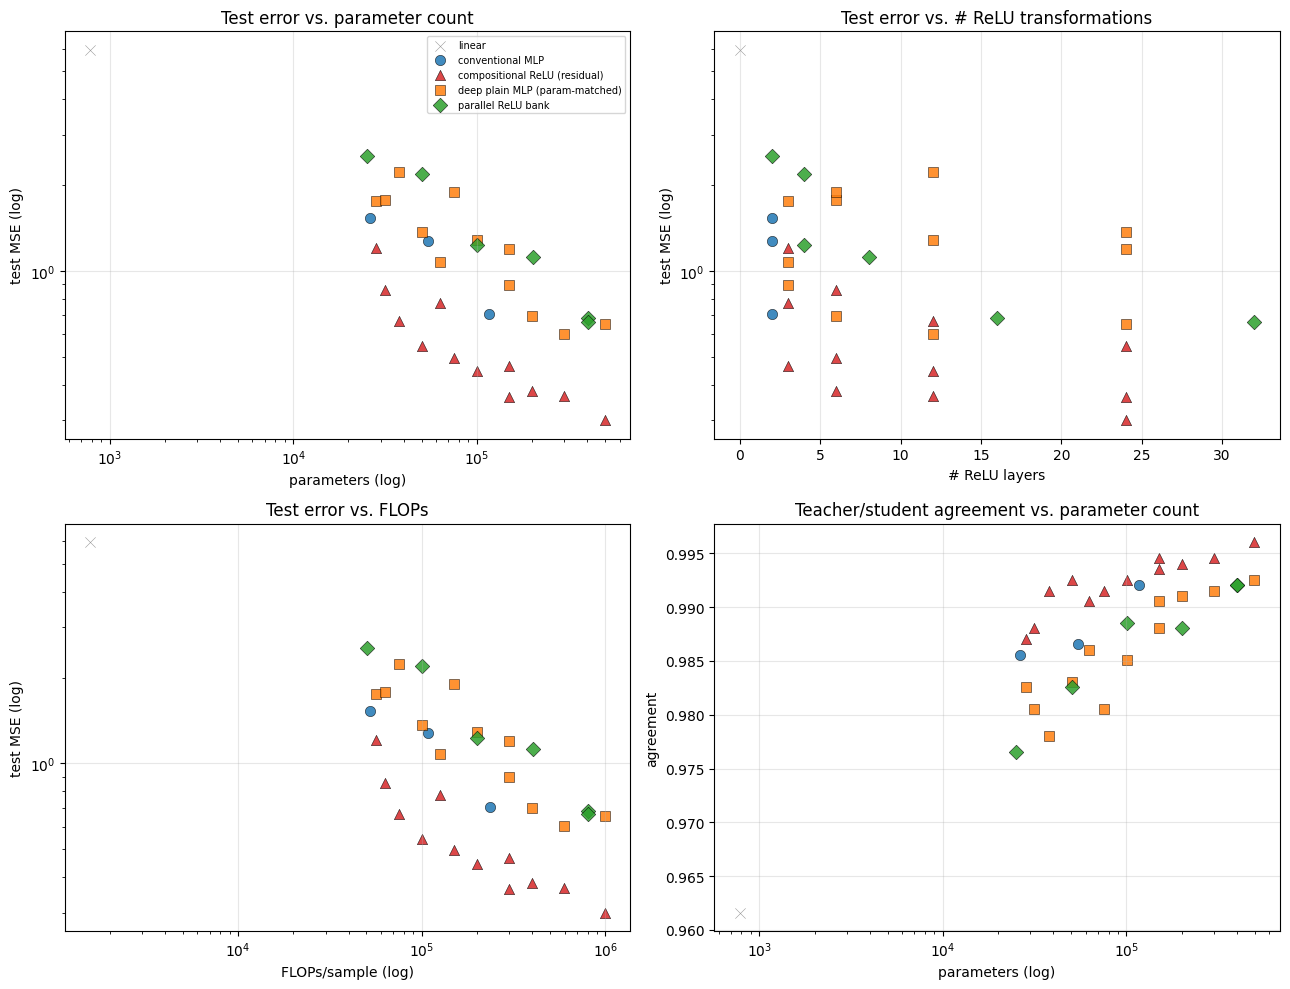

In [3]:
def scatter_by_arch(ax, x_key, y_key, logx=False, logy=False):
    seen = set()
    for r in results:
        style = ARCH_STYLE[r["arch"]]
        label = style["label"] if r["arch"] not in seen else None
        seen.add(r["arch"])
        ax.scatter(r[x_key], r[y_key], color=style["color"], marker=style["marker"],
                   s=55, alpha=0.85, label=label, edgecolors="black" if style["marker"] != "x" else None, linewidths=0.4)
    if logx: ax.set_xscale("log")
    if logy: ax.set_yscale("log")
    ax.grid(True, alpha=0.3)


fig, axes = plt.subplots(2, 2, figsize=(13, 10))

scatter_by_arch(axes[0, 0], "n_params", "test_mse", logx=True, logy=True)
axes[0, 0].set_xlabel("parameters (log)"); axes[0, 0].set_ylabel("test MSE (log)")
axes[0, 0].set_title("Test error vs. parameter count")
axes[0, 0].legend(fontsize=7)

scatter_by_arch(axes[0, 1], "n_relu_layers", "test_mse", logy=True)
axes[0, 1].set_xlabel("# ReLU layers"); axes[0, 1].set_ylabel("test MSE (log)")
axes[0, 1].set_title("Test error vs. # ReLU transformations")

scatter_by_arch(axes[1, 0], "flops_per_sample", "test_mse", logx=True, logy=True)
axes[1, 0].set_xlabel("FLOPs/sample (log)"); axes[1, 0].set_ylabel("test MSE (log)")
axes[1, 0].set_title("Test error vs. FLOPs")

scatter_by_arch(axes[1, 1], "n_params", "test_teacher_student_agreement", logx=True)
axes[1, 1].set_xlabel("parameters (log)"); axes[1, 1].set_ylabel("agreement")
axes[1, 1].set_title("Teacher/student agreement vs. parameter count")

fig.tight_layout()
plt.show()

## The core ablation, replicated a third time -- with a twist

Residual composition beats parameter-matched plain depth at every (H, N)
pair, by the widest margin seen across all three distillation experiments
(up to 3.3x at H=64,N=8). But unlike experiments 05/07, the plain model's
degradation is noisy rather than monotonic -- it peaks mid-grid instead of
declining steadily with depth. The headline finding replicates; its exact
visual signature doesn't.

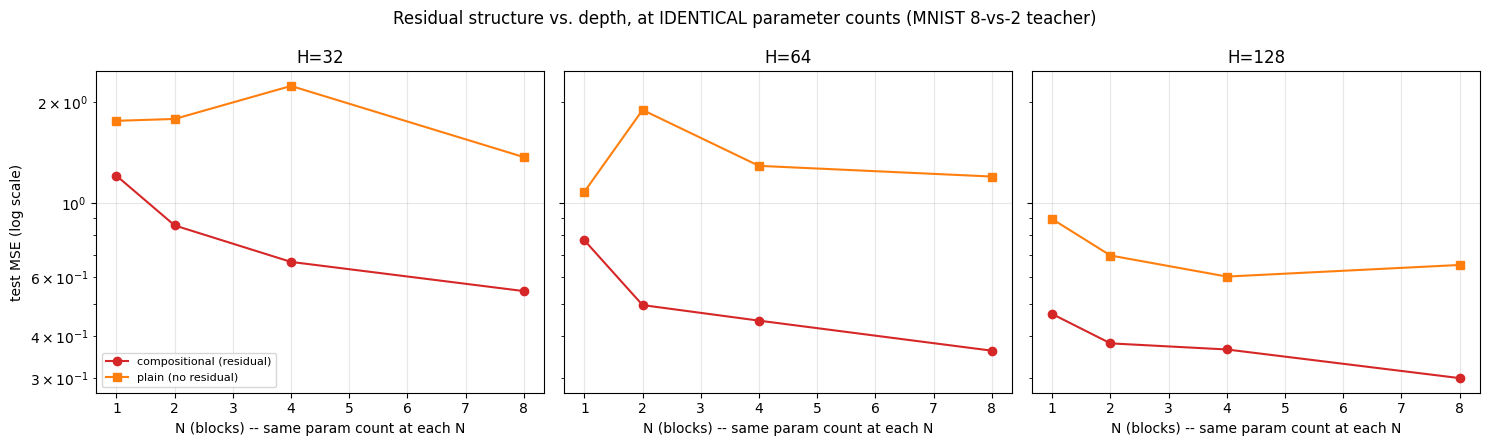

In [4]:
from collections import defaultdict

by_h = defaultdict(lambda: defaultdict(dict))
for r in results:
    if r["arch"] in ("compositional_relu", "deep_plain_mlp"):
        h = int(r["cfg_hidden"])
        n = int(r["cfg_n_blocks"]) if r["arch"] == "compositional_relu" else int(r["cfg_n_layers"]) // 3
        by_h[h][n][r["arch"]] = r["test_mse"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, h in zip(axes, sorted(by_h)):
    ns = sorted(by_h[h])
    comp = [by_h[h][n].get("compositional_relu") for n in ns]
    plain = [by_h[h][n].get("deep_plain_mlp") for n in ns]
    ax.plot(ns, comp, "o-", color=ARCH_STYLE["compositional_relu"]["color"], label="compositional (residual)")
    ax.plot(ns, plain, "s-", color=ARCH_STYLE["deep_plain_mlp"]["color"], label="plain (no residual)")
    ax.set_title(f"H={h}")
    ax.set_xlabel("N (blocks) -- same param count at each N")
    ax.set_yscale("log")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("test MSE (log scale)")
axes[0].legend(fontsize=8)
fig.suptitle("Residual structure vs. depth, at IDENTICAL parameter counts (MNIST 8-vs-2 teacher)")
fig.tight_layout()
plt.show()

## Robustness: the Gaussian-noise exception, a third time

Compositional wins clean/translation/rotation/brightness -- but is
essentially tied with the plain model under Gaussian noise. Three for
three now, across MNIST-imbalanced, CIFAR-10, and MNIST-balanced teachers.

In [5]:
with open(OUTPUTS / "robustness_results.csv") as f:
    rob_rows = list(csv.DictReader(f))

conditions = ["clean_test", "translate_2px", "rotate_10deg", "gaussian_noise", "brightness_1.3x"]
models_order = ["linear", "conventional_mlp_H128", "deepplain_H128_N8", "compositional_H128_N8", "parallel_B32_W16"]

header = f'{"model":24s}' + "".join(f'{c:>18s}' for c in conditions)
print(header)
for m in models_order:
    row = {r["condition"]: float(r["mse"]) for r in rob_rows if r["model"] == m}
    print(f'{m:24s}' + "".join(f'{row.get(c, float("nan")):18.2f}' for c in conditions))

model                           clean_test     translate_2px      rotate_10deg    gaussian_noise   brightness_1.3x
linear                                5.88             10.41              5.84              6.32              6.50
conventional_mlp_H128                 0.74              2.61              1.02              1.10              0.90
deepplain_H128_N8                     0.68              2.12              0.66              1.01              0.87
compositional_H128_N8                 0.31              1.48              0.45              0.93              0.35
parallel_B32_W16                      0.68              2.83              1.01              2.20              0.81


## Ground-truth task evaluation: a completely different story from CIFAR-10

Unlike experiment 07 (where the smallest MLP kept only 19.8% of the
teacher's recall), here even the smallest MLP recovers 98.0% test accuracy
against the teacher's 99.2%. A clean, single-boundary function is far more
forgiving to distill down to a small student.

In [6]:
for name in ["conventional_mlp_H32", "compositional_H128_N8"]:
    path = OUTPUTS / f"ground_truth_eval_{name}.csv"
    with open(path) as f:
        rows = list(csv.DictReader(f))
    test_row = next(r for r in rows if r["split"] == "test" and r["who"] == "student")
    teacher_row = next(r for r in rows if r["split"] == "test" and r["who"] == "teacher")
    print(f"{name}: student acc={float(test_row['accuracy']):.4f} recall={float(test_row['recall']):.4f}  "
          f"(teacher acc={float(teacher_row['accuracy']):.4f} recall={float(teacher_row['recall']):.4f})")

conventional_mlp_H32: student acc=0.9796 recall=0.9918  (teacher acc=0.9920 recall=0.9959)
compositional_H128_N8: student acc=0.9880 recall=0.9938  (teacher acc=0.9920 recall=0.9959)


## Worst-case disagreements

Much smaller in absolute magnitude than experiment 05's (max |error| ~2.85
vs. ~5.47), and dominated by genuine near-boundary ambiguity -- 3 of the
top 5 are real classification disagreements, all on digits the *teacher
itself* was only mildly confident about.

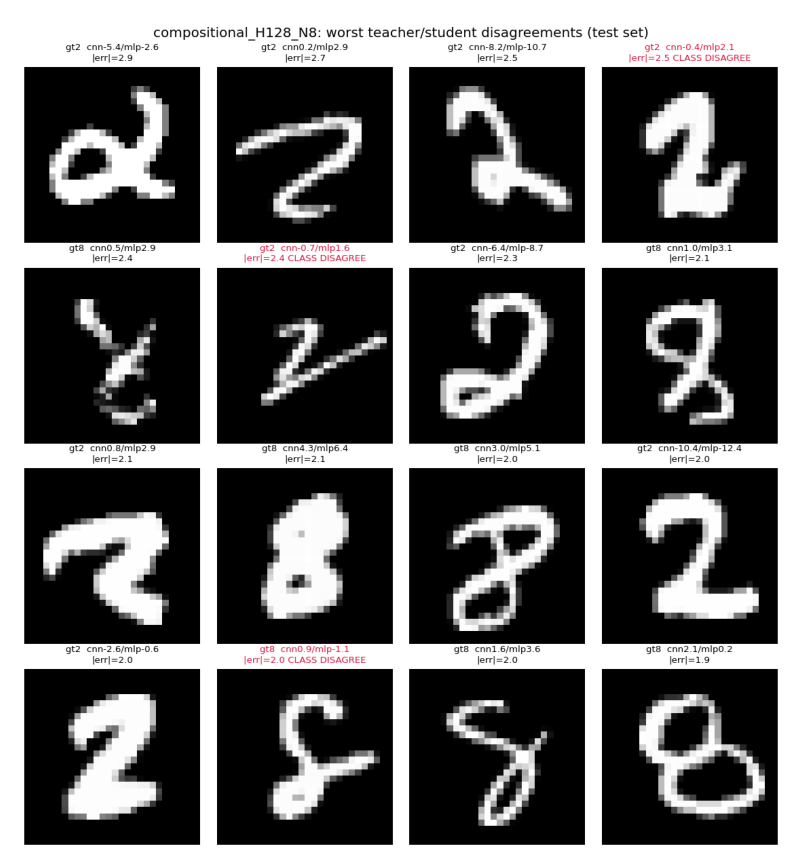

In [7]:
img = mpimg.imread(OUTPUTS / "worst_cases" / "compositional_H128_N8_worst_cases.png")
plt.figure(figsize=(11, 11))
plt.imshow(img)
plt.axis("off")
plt.show()

## Takeaways

- **Decision-boundary cleanliness, not task difficulty, drives
  distillability.** This teacher isn't an obviously *easier* classification
  problem than experiment 05's (8 vs. one similar digit vs. 8 vs. nine
  mixed digits) -- but its function is over 3x easier to distill, and a
  26k-parameter student recovers nearly all of its task performance. Task
  difficulty and function-representation difficulty are different axes.
- **Composition beats plain depth and parallel width, a third time** --
  the widest margin yet, though the plain model's failure mode looks
  different here (noisy, not monotonic) than on the other two teachers.
- **The Gaussian-noise exception is now 3-for-3** across totally different
  teachers -- the most consistent finding across the whole distillation
  series, and probably the most trustworthy one.

Full write-up: `experiments/09_function_distillation_8_vs_2/README.md`.